# what is the probability of a D20 landing on a number higher than 15? 
whats the chance of a NAT one roll

### D20 rolling 15+
Describe your simulation here:
1. simulating EVENTS for probability you AUTO-FAIL your action or have a likely chance to sucseed (dnd) via rolling a d20 (20 sided die)
2. each trial wil be a dice roll, they ill be inputed into a graph to show each trial and what it rolled, from there all numbers between 1 and 15 will be filtered out and counted, then 1 will be filtered into its own group. rolls with 15 or higher will then be inserted into a relative frequency/ probability graph to answer the question. the same will be done for the number 1
3. normally within dnd rolls of 15 or higher give a really good chance at succseeding, 10-14 give you a it sorta worked outcome (most of the time depending on your dm) and anything under 10 is a questionable result at best and a hilarious fail most often. nat ones are just histaricall becuase they are considered an AUTO fail and often result with a terrible turn of events. The goal is to figure out what your chance of auto failing vs sucseeding are

In [2]:
### My Analysis
# First, write the code you need to simulate rolling your die 1000 times.
# Then, write the code you need to estimate a probability from the simulated data.
# Finally, write the code you need to calculate a theoretical probability.
# Add as many cells as you need for your analysis

=== FINAL EXPERIMENTAL PERCENTAGES (AT 2,000 ROLLS) ===
Run 1: Success (15+) = 30.95% | Auto-Fail (1) = 4.55%
Run 2: Success (15+) = 32.30% | Auto-Fail (1) = 4.05%
Run 3: Success (15+) = 32.05% | Auto-Fail (1) = 5.80%
Run 4: Success (15+) = 31.95% | Auto-Fail (1) = 4.45%
Run 5: Success (15+) = 29.55% | Auto-Fail (1) = 5.60%

=== OVERALL EXPERIMENTAL PERCENTAGE (ALL 10,000 ROLLS) ===
Overall Success (15+): 31.36% (Theoretical: 30.00%)
Overall Auto-Fail (1):  4.89% (Theoretical: 5.00%)



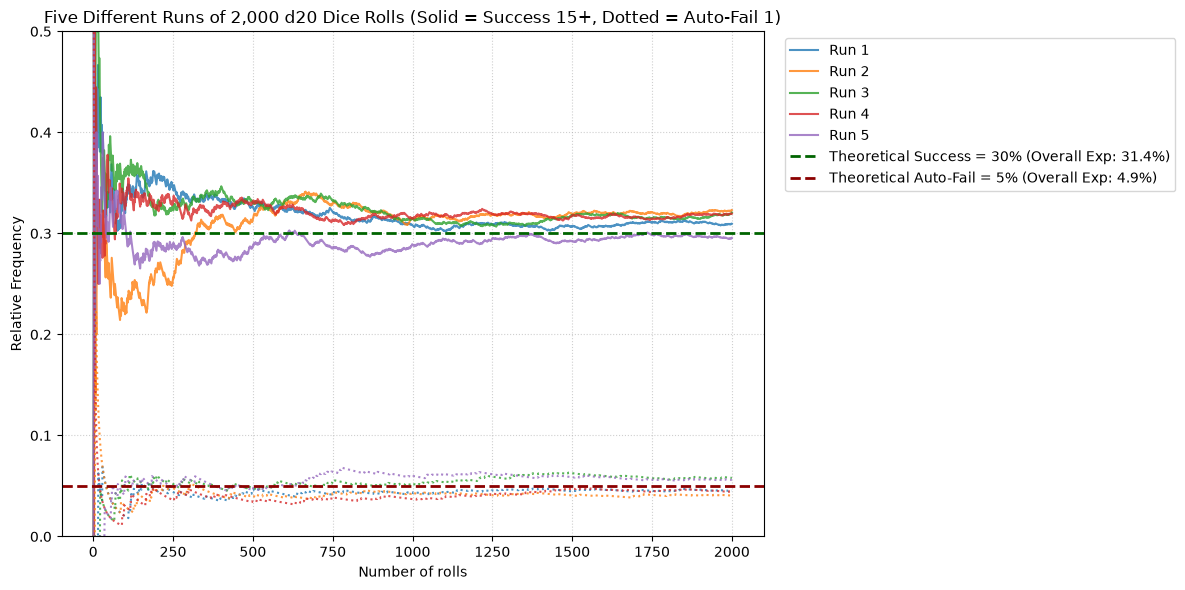

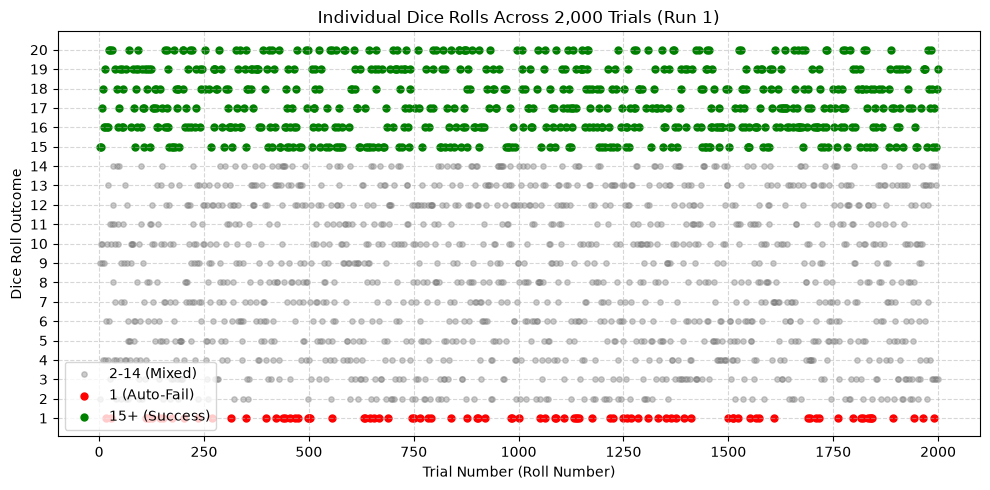

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================
# 1. RUN 5 SIMULATIONS (2,000 ROLLS EACH)
# ==========================================
num_trials = 2000
all_runs = []

for run in range(1, 6):
    # Roll a 20-sided die 2,000 times
    rolls = np.random.randint(1, 21, size=num_trials)

    df_run = pd.DataFrame(
        {"flip_number": np.arange(1, num_trials + 1), "roll": rolls}
    )

    # Outcome indicators
    df_run["is_auto_fail"] = df_run["roll"] == 1
    df_run["is_success"] = df_run["roll"] >= 15

    # Cumulative relative frequencies
    df_run["rel_freq_success"] = (
        df_run["is_success"].cumsum() / df_run["flip_number"]
    )
    df_run["rel_freq_auto_fail"] = (
        df_run["is_auto_fail"].cumsum() / df_run["flip_number"]
    )
    df_run["run"] = f"Run {run}"

    all_runs.append(df_run)

# Concatenate all 5 runs into a single DataFrame
all_runs = pd.concat(all_runs, ignore_index=True)

# ==========================================
# 2. DISPLAY EXPERIMENTAL VS THEORETICAL %
# ==========================================
print("=== FINAL EXPERIMENTAL PERCENTAGES (AT 2,000 ROLLS) ===")
for run_name, group in all_runs.groupby("run"):
    final_success_pct = group["rel_freq_success"].iloc[-1] * 100
    final_fail_pct = group["rel_freq_auto_fail"].iloc[-1] * 100
    print(
        f"{run_name}: Success (15+) = {final_success_pct:.2f}% | Auto-Fail (1) = {final_fail_pct:.2f}%"
    )

# Calculate overall average experimental percentage across all 5 runs (10,000 total rolls)
overall_success_pct = (all_runs["roll"] >= 15).mean() * 100
overall_fail_pct = (all_runs["roll"] == 1).mean() * 100

print("\n=== OVERALL EXPERIMENTAL PERCENTAGE (ALL 10,000 ROLLS) ===")
print(f"Overall Success (15+): {overall_success_pct:.2f}% (Theoretical: 30.00%)")
print(f"Overall Auto-Fail (1):  {overall_fail_pct:.2f}% (Theoretical: 5.00%)\n")

# ==========================================
# 3. MULTI-RUN RELATIVE FREQUENCY LINE PLOT
# ==========================================
plt.figure(figsize=(12, 6))

# Plot lines for Success (15+) across all 5 runs
sns.lineplot(
    data=all_runs,
    x="flip_number",
    y="rel_freq_success",
    hue="run",
    palette="tab10",
    alpha=0.8,
)

# Plot lines for Auto-Fail (1) across all 5 runs
sns.lineplot(
    data=all_runs,
    x="flip_number",
    y="rel_freq_auto_fail",
    hue="run",
    palette="tab10",
    legend=False,
    linestyle=":",
    alpha=0.8,
)

# Reference lines for theoretical probabilities
plt.axhline(
    6 / 20,
    color="darkgreen",
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Success = 30% (Overall Exp: {overall_success_pct:.1f}%)",
)
plt.axhline(
    1 / 20,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Auto-Fail = 5% (Overall Exp: {overall_fail_pct:.1f}%)",
)

plt.title("Five Different Runs of 2,000 d20 Dice Rolls (Solid = Success 15+, Dotted = Auto-Fail 1)")
plt.xlabel("Number of rolls")
plt.ylabel("Relative Frequency")
plt.ylim(0, 0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# ==========================================
# 4. INDIVIDUAL ROLLS SCATTER PLOT (RUN 1)
# ==========================================
run_1_df = all_runs[all_runs["run"] == "Run 1"]

plt.figure(figsize=(10, 5))

plt.scatter(
    run_1_df.loc[
        (run_1_df["roll"] > 1) & (run_1_df["roll"] < 15), "flip_number"
    ],
    run_1_df.loc[(run_1_df["roll"] > 1) & (run_1_df["roll"] < 15), "roll"],
    color="gray",
    alpha=0.4,
    s=15,
    label="2-14 (Mixed)",
)

plt.scatter(
    run_1_df.loc[run_1_df["roll"] == 1, "flip_number"],
    run_1_df.loc[run_1_df["roll"] == 1, "roll"],
    color="red",
    s=25,
    label="1 (Auto-Fail)",
)

plt.scatter(
    run_1_df.loc[run_1_df["roll"] >= 15, "flip_number"],
    run_1_df.loc[run_1_df["roll"] >= 15, "roll"],
    color="green",
    s=25,
    label="15+ (Success)",
)

plt.title("Individual Dice Rolls Across 2,000 Trials (Run 1)")
plt.xlabel("Trial Number (Roll Number)")
plt.ylabel("Dice Roll Outcome")
plt.yticks(range(1, 21))
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Conclusion.
The experimental probability that you would roll a 15 or higher, which is being considered as a succsessfull action is 31.36 percent. The theoretical value for this is 30%, as 15,16,17,18,19,20 is 6 diffrent outcomes. with 20 diffrent outcomes possible and 6 being counted for the event. (6/20) is 30 precent. so the experimental probability is not far from the theoretical. Simmilarly the probability of rolling a 1, which will be considered an auto fail is 1/20 or 5% in theory. within this experiment however the result was closer to a 4.89% meaning unlike the experimental probability of a succsessfull action this data would suggest that you are less likely to automatically fail an action in actuallity than in theory. but in neither case are the emperical values more than 1.5% off of the theoretical values. our precent error for each would be 31.36-30/30 x 100 or 4.5% and 4.89-5/5 x 100 or -2.2% both values are well within an resonable range for precent error. 
## graph interpretation
as the number of rolls increases toward 2,000 in each run, the line fluctuations flatten out. interestingly however, run 5 dipped to a low point on successfull roll around roll 100, Inversly run 2 increased its RFQ as it approached 1000 rolls and leveled out as it approached 2000.
Despite several of the runs getting close to the therotical they all trended higher than expected or in the case of run 5, slightly lower. 
## to answer the question 
 both visual evidence and simulated data confirm the theoretical odds: an auto-fail is a relatively rare event ($1$ in $20$), whereas a success happens regularly ($3$ out of every $10$ rolls).